# Facial Emotion Recognition with CNN — FER2013
## Starter Notebook

</div>

---
## 📖 About the Dataset

**Source:** [FER2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

FER2013 (*Facial Expression Recognition 2013*) was introduced in a Kaggle competition in 2013 as part of the ICML workshop *"Challenges in Representation Learning"*. The faces were collected automatically from Google image search, so they are **real-world faces**: different ages, poses, lighting, glasses, hands covering the face, etc.

| Property | Value |
|---|---|
| Total images | ~35,900 |
| Image size | **48 × 48 pixels** |
| Color | **Grayscale** (1 channel) |
| Classes | **7 emotions** |
| Train / Test | ~28,700 / ~7,200 images |
| Format | `.jpg` files in one folder per class |

**The 7 classes:** `angry` 😠 · `disgust` 🤢 · `fear` 😨 · `happy` 😄 · `neutral` 😐 · `sad` 😢 · `surprise` 😲

**Folder structure:**
```
fer2013/
├── train/
│   ├── angry/     ├── disgust/   ├── fear/   ├── happy/
│   ├── neutral/   ├── sad/       └── surprise/
└── test/
    └── (same 7 folders)
```

### ⚠️ Things to know before you start
1. **The classes are imbalanced** — `happy` has ~7,000 training images while `disgust` has only ~400. A model can get "good" accuracy just by ignoring the rare classes, so look at **per-class** results, not only overall accuracy.
2. **The task is hard** — the images are small and blurry, and some emotions look alike (fear vs. surprise, sad vs. neutral). Human accuracy on this dataset is estimated at only **~65%**, so don't expect 95%!
3. **There is no validation set** — we will create one from the training set.
4. **Some labels are noisy** — a few images are mislabeled or are not faces at all.

<div dir="rtl">

---
## 📖 نبذة عن البيانات

**المصدر:** [FER2013 على Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

بيانات FER2013 (*التعرّف على تعابير الوجه 2013*) نُشرت في مسابقة على Kaggle عام 2013 ضمن ورشة ICML بعنوان *"تحديات تعلّم التمثيلات"*. جُمعت الوجوه تلقائياً من بحث صور Google، لذلك هي **وجوه من الواقع**: أعمار مختلفة، وضعيات مختلفة، إضاءة متفاوتة، نظارات، أيدٍ تغطي الوجه... إلخ.

| الخاصية | القيمة |
|---|---|
| عدد الصور الكلي | حوالي 35,900 |
| حجم الصورة | **48 × 48 بكسل** |
| الألوان | **رمادية (Grayscale)** — قناة واحدة |
| عدد الأصناف | **7 مشاعر** |
| تدريب / اختبار | حوالي 28,700 / 7,200 صورة |
| الصيغة | ملفات `.jpg` في مجلد لكل صنف |

**الأصناف السبعة:** `angry` غضب 😠 · `disgust` اشمئزاز 🤢 · `fear` خوف 😨 · `happy` سعادة 😄 · `neutral` محايد 😐 · `sad` حزن 😢 · `surprise` مفاجأة 😲

### ⚠️ أمور مهمة قبل البدء
1. **الأصناف غير متوازنة** — صنف `happy` فيه حوالي 7,000 صورة تدريب بينما `disgust` فيه حوالي 400 فقط. النموذج قد يحصل على دقة "جيدة" وهو يتجاهل الأصناف النادرة، لذلك انظر إلى النتائج **لكل صنف** وليس الدقة الكلية فقط.
2. **المهمة صعبة** — الصور صغيرة وغير واضحة، وبعض المشاعر متشابهة (الخوف والمفاجأة، الحزن والمحايد). دقة الإنسان على هذه البيانات تُقدّر بحوالي **65%** فقط، فلا تتوقع 95%!
3. **لا توجد بيانات تحقق (validation)** — سننشئها من بيانات التدريب.
4. **بعض التسميات فيها أخطاء** — بعض الصور مصنّفة خطأ أو ليست وجوهاً أصلاً.

</div>

---
## 1. Setup
> In Colab, enable the GPU: **Runtime → Change runtime type → T4 GPU**

<div dir="rtl">

## 1. الإعداد
> في Colab فعّل الـ GPU من: **Runtime → Change runtime type → T4 GPU**

</div>

In [2]:
# Install kagglehub (used to download datasets from Kaggle)
# تثبيت مكتبة kagglehub لتحميل البيانات من Kaggle
!pip install -q kagglehub

In [3]:
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

# ---- Reproducibility: same random results every run ----
# ---- تثبيت العشوائية: نفس النتائج في كل تشغيل ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if available, otherwise the CPU
# استخدم الـ GPU إن وُجد، وإلا الـ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Download the Data
We use `kagglehub` to download the dataset directly from Kaggle.
> If you get an authentication error: in Colab open 🔑 **Secrets** and add `KAGGLE_USERNAME` and `KAGGLE_KEY` (from Kaggle → Settings → API → Create New Token).

<div dir="rtl">

## 2. تحميل البيانات
نستخدم `kagglehub` لتحميل البيانات مباشرة من Kaggle.
> إذا ظهر خطأ في الصلاحيات: من Colab افتح 🔑 **Secrets** وأضف `KAGGLE_USERNAME` و `KAGGLE_KEY` (من Kaggle ← Settings ← API ← Create New Token).

</div>

In [4]:
import kagglehub

# Download the dataset (it is cached, so running again is instant)
# تحميل البيانات (تُحفظ مؤقتاً، فإعادة التشغيل تكون فورية)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

# Locate the train/ and test/ folders
# تحديد مسار مجلدي التدريب والاختبار
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR  = os.path.join(path, "test")
print("Train folder:", TRAIN_DIR, "| exists:", os.path.isdir(TRAIN_DIR))
print("Test folder: ", TEST_DIR,  "| exists:", os.path.isdir(TEST_DIR))
print("Class folders:", sorted(os.listdir(TRAIN_DIR)))

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Train folder: /kaggle/input/fer2013/train | exists: True
Test folder:  /kaggle/input/fer2013/test | exists: True
Class folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Explore the Data

<div dir="rtl">

## 3. استكشاف البيانات

</div>

In [5]:
# ImageFolder reads a "one folder per class" structure:
# the folder name becomes the class name, and each image gets that label.
# ImageFolder يقرأ البيانات المنظّمة بمجلد لكل صنف:
# اسم المجلد يصبح اسم الصنف، وكل صورة تأخذ تسمية مجلدها.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = raw_train.classes          # ['angry', 'disgust', 'fear', ...]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Train images:", len(raw_train))
print("Test images: ", len(raw_test))

# Check the size and mode of one image (L = grayscale)
# فحص حجم ونوع صورة واحدة (L تعني رمادية)
img, label = raw_train[0]
print("Image size:", img.size, "| mode:", img.mode, "| label:", CLASS_NAMES[label])

Classes: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}
Train images: 28709
Test images:  7178
Image size: (48, 48) | mode: RGB | label: angry


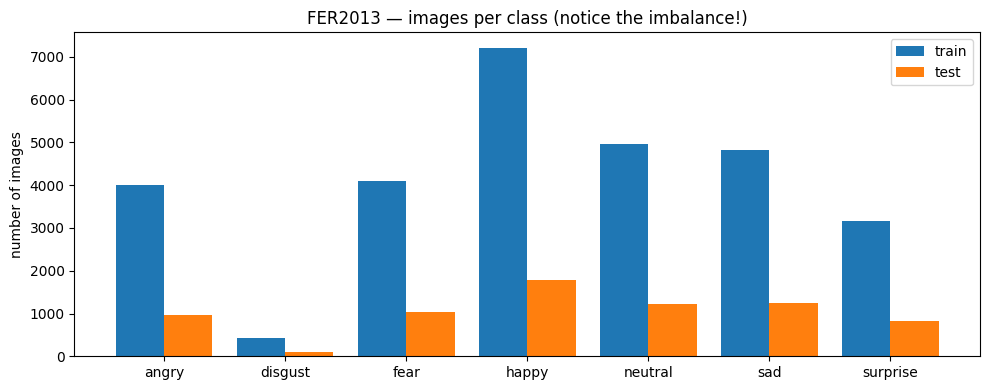

angry      train:  3995   test:   958
disgust    train:   436   test:   111
fear       train:  4097   test:  1024
happy      train:  7215   test:  1774
neutral    train:  4965   test:  1233
sad        train:  4830   test:  1247
surprise   train:  3171   test:   831


In [5]:
# ---- Class distribution: how many images per emotion? ----
# ---- توزيع الأصناف: كم صورة لكل شعور؟ ----
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)

x = np.arange(NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(NUM_CLASSES)], width=0.4, label="train")
plt.bar(x + 0.2, [test_counts[i]  for i in range(NUM_CLASSES)], width=0.4, label="test")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("number of images")
plt.title("FER2013 — images per class (notice the imbalance!)")
plt.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<10} train: {train_counts[i]:>5}   test: {test_counts[i]:>5}")

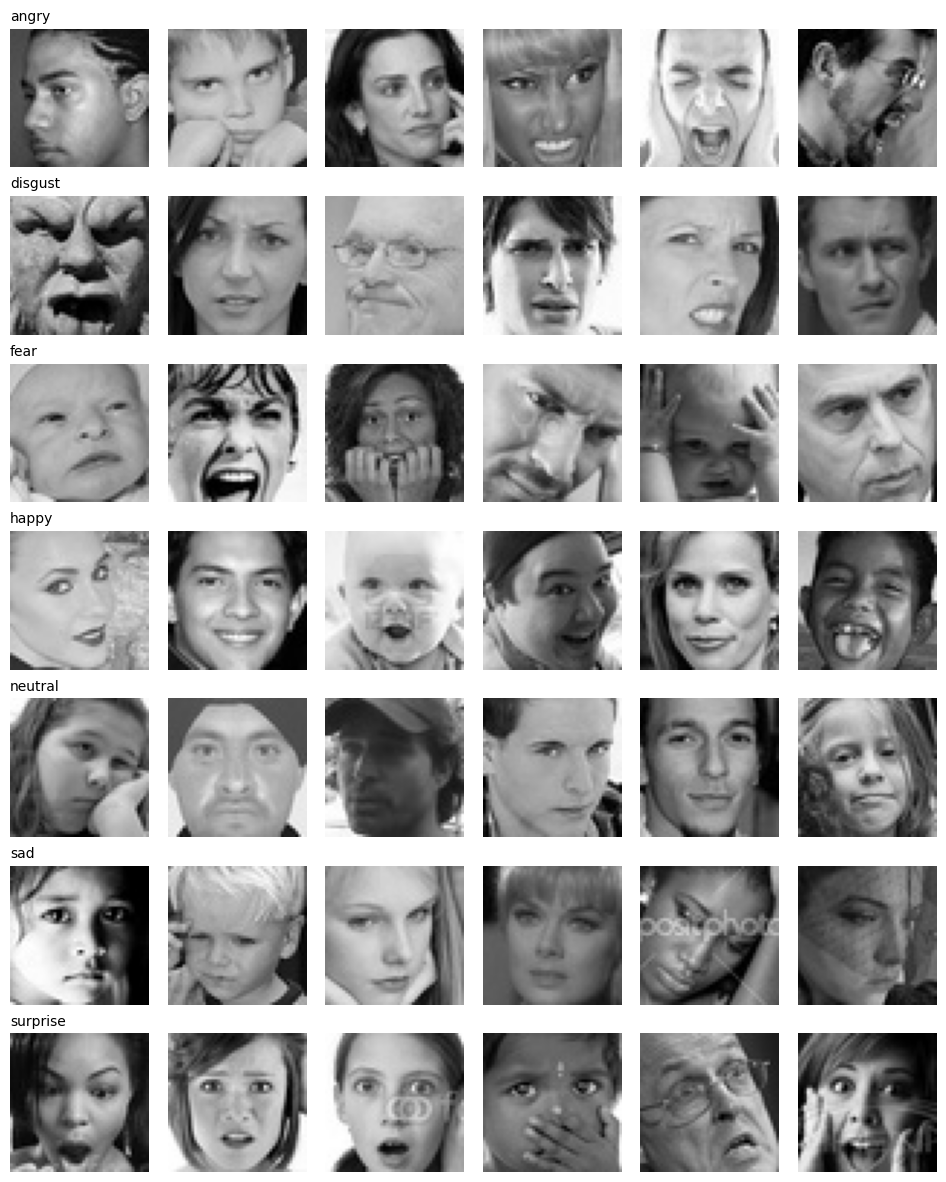

In [6]:
# ---- Show random examples from each class ----
# ---- عرض أمثلة عشوائية من كل صنف ----
N_PER_CLASS = 6
train_targets = np.array(raw_train.targets)

fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, NUM_CLASSES * 1.7))
for c in range(NUM_CLASSES):
    # pick random image indices that belong to class c
    # اختيار صور عشوائية تنتمي للصنف c
    idxs = np.random.choice(np.where(train_targets == c)[0], N_PER_CLASS, replace=False)
    for j, idx in enumerate(idxs):
        img, _ = raw_train[idx]
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Validation Split + Class Weights
created validation set (15%) out of the training set. The **test set is touched only once at the end** for each model.

In [6]:
import time
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix, f1_score

targets = np.array(raw_train.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.15, stratify=targets, random_state=SEED
)
print("train:", len(train_idx), "| val:", len(val_idx), "| test:", len(raw_test))

# Class weights: rare classes (disgust) get a bigger weight in the loss
# أوزان الأصناف: الأصناف النادرة تأخذ وزناً أكبر في دالة الخسارة
cnt = np.bincount(targets[train_idx], minlength=NUM_CLASSES)
class_weights = torch.tensor(len(train_idx) / (NUM_CLASSES * cnt), dtype=torch.float32).to(device)
print({c: round(float(w), 2) for c, w in zip(CLASS_NAMES, class_weights.cpu())})

criterion = nn.CrossEntropyLoss(weight=class_weights)

train: 24402 | val: 4307 | test: 7178
{'angry': 1.03, 'disgust': 9.4, 'fear': 1.0, 'happy': 0.57, 'neutral': 0.83, 'sad': 0.85, 'surprise': 1.29}


In [7]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/fer2013_project"
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
from collections import Counter

print("Class mapping:", raw_train.class_to_idx)
print("Class names:", raw_train.classes)

train_counts = Counter(
    raw_train.targets[i] for i in train_idx
)
val_counts = Counter(
    raw_train.targets[i] for i in val_idx
)
test_counts = Counter(raw_test.targets)

for i, name in enumerate(raw_train.classes):
    print(
        f"{name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Val: {val_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

Class mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Class names: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
angry        | Train:  3396 | Val:   599 | Test:   958
disgust      | Train:   371 | Val:    65 | Test:   111
fear         | Train:  3482 | Val:   615 | Test:  1024
happy        | Train:  6133 | Val:  1082 | Test:  1774
neutral      | Train:  4220 | Val:   745 | Test:  1233
sad          | Train:  4105 | Val:   725 | Test:  1247
surprise     | Train:  2695 | Val:   476 | Test:   831


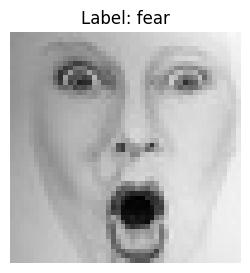

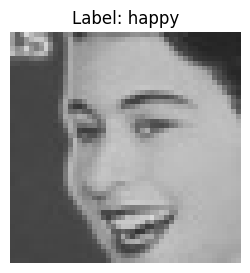

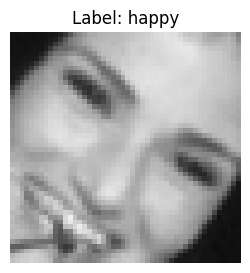

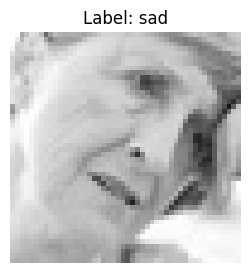

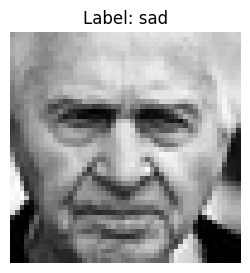

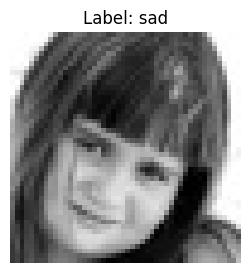

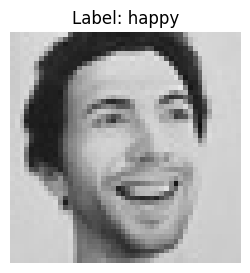

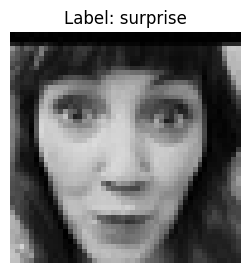

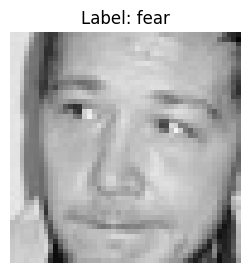

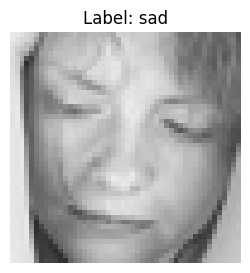

In [ ]:
import matplotlib.pyplot as plt

for i in range(10):
    img, label = raw_train[train_idx[i]]

    plt.figure(figsize=(3, 3))
    plt.imshow(img, cmap="gray")
    plt.title(f"Label: {raw_train.classes[label]}")
    plt.axis("off")
    plt.show()

## 5. Data Pipelines
We need **two** pipelines:
- **From scratch:** keep the images as they are (48×48, 1 channel).
- **Pretrained models:** they were trained on ImageNet, so we need 3 channels, a bigger size, and ImageNet normalization.



In [8]:
from torch.utils.data import Dataset

IMG_SIZE   = 128   # use 224 for (slightly) better accuracy but slower training | 224 أدق لكن أبطأ
BATCH_SIZE = 128

class TransformSubset(Dataset):
    """Apply a different transform to each split (train aug vs. eval).
    يطبّق تحويلات مختلفة لكل جزء (تدريب فيه augmentation، والبقية لا)."""
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, y = self.base[self.indices[i]]          # PIL image, label
        return self.transform(img), y

# ---- Pipeline A: from scratch (1 x 48 x 48) ----
scratch_train_tf = transforms.Compose([
    transforms.Grayscale(1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
    transforms.RandomErasing(p=0.2),
])
scratch_eval_tf = transforms.Compose([
    transforms.Grayscale(1), transforms.ToTensor(), transforms.Normalize([0.5], [0.5]),
])

# ---- Pipeline B: pretrained (3 x IMG_SIZE x IMG_SIZE, ImageNet stats) ----
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
pre_train_tf = transforms.Compose([
    transforms.Grayscale(3),                 # gray -> 3 channels | رمادي إلى 3 قنوات
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
pre_eval_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])

def make_loaders(train_tf, eval_tf):
    kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
    tr = DataLoader(TransformSubset(raw_train, train_idx, train_tf), shuffle=True,  **kw)
    va = DataLoader(TransformSubset(raw_train, val_idx,   eval_tf),  shuffle=False, **kw)
    te = DataLoader(TransformSubset(raw_test, range(len(raw_test)), eval_tf), shuffle=False, **kw)
    return tr, va, te

scratch_loaders = make_loaders(scratch_train_tf, scratch_eval_tf)
pre_loaders     = make_loaders(pre_train_tf, pre_eval_tf)

x, y = next(iter(scratch_loaders[0])); print("scratch batch:", x.shape)
x, y = next(iter(pre_loaders[0]));     print("pretrained batch:", x.shape)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


scratch batch: torch.Size([128, 1, 48, 48])
pretrained batch: torch.Size([128, 3, 128, 128])


## 6. Training & Evaluation Helpers
One `fit()` function is reused for **all three** models, so the comparison is fair. It keeps the best weights (by validation accuracy) and stops early if there is no improvement.



In [9]:
use_amp = device.type == "cuda"
scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    # Keep frozen BatchNorm layers in evaluation mode
    if training:
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                params = list(module.parameters(recurse=False))
                if params and not any(p.requires_grad for p in params):
                    module.eval()

    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type, enabled=use_amp
            ):
                out = model(x)
                loss = criterion(out, y)

            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += y.size(0)

    return total_loss / n, 100 * correct / n


def fit(model, name, loaders, optimizer, epochs, patience=6, history=None):
    train_loader, val_loader, _ = loaders
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    h = history or {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state, wait, t0 = -1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, optimizer)
        vl, va = run_epoch(model, val_loader)
        scheduler.step(vl)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {tl:.3f} acc {ta:.1f}% | val loss {vl:.3f} acc {va:.1f}%")

        if va > best_acc:
           best_acc, wait = va, 0
           best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
           torch.save(best_state, f"{SAVE_DIR}/{name.replace(' ', '_')}.pt")   # السطر الجديد

        else:
            wait += 1
            if wait >= patience:
                print(f"[{name}] early stopping (no val improvement for {patience} epochs)")
                break

    model.load_state_dict(best_state)          # go back to the best epoch
    h["best_val_acc"], h["time_min"] = best_acc, (time.time() - t0) / 60 + h.get("time_min", 0)
    return h


def plot_history(h, title):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val")
    ax[0].set_title(f"{title} — loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="val")
    ax[1].set_title(f"{title} — accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()


@torch.no_grad()
def evaluate_test(model, test_loader, name):
    """Final evaluation on the TEST set: accuracy, macro-F1, per-class report, confusion matrix."""
    model.eval()
    preds, labels = [], []
    for x, y in test_loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x.to(device))
        preds.append(out.argmax(1).cpu()); labels.append(y)
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()

    acc = 100 * (preds == labels).mean()
    f1  = 100 * f1_score(labels, preds, average="macro")
    print(f"\n=== {name} | TEST accuracy {acc:.2f}% | macro-F1 {f1:.2f}% ===")
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=3))

    cm = confusion_matrix(labels, preds, normalize="true")
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45); plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                     color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"{name} — confusion matrix (normalized)")
    plt.tight_layout(); plt.show()
    return {"test_acc": acc, "macro_f1": f1}


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

import json
RES_PATH = f"{SAVE_DIR}/results.json"
results = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}

## 7. Model 1 — CNN from Scratch
A small CNN, and train from **random weights**: 4 blocks of (Conv→BN→ReLU)×2 → MaxPool → Dropout, then a small classifier. Input is 1×48×48.


In [13]:
def conv_block(c_in, c_out, p_drop):
    return nn.Sequential(
        nn.Conv2d(c_in,  c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p_drop),
    )

class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(          # 48 -> 24 -> 12 -> 6 -> 3
            conv_block(1,   32,  0.10),
            conv_block(32,  64,  0.15),
            conv_block(64,  128, 0.20),
            conv_block(128, 256, 0.25),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 256), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

scratch_model = EmotionCNN(NUM_CLASSES).to(device)
total, trainable = count_params(scratch_model)
print(f"Params: {total:,} (trainable {trainable:,})")

Params: 1,240,231 (trainable 1,240,231)


[Scratch CNN] epoch 01/40 | train loss 1.913 acc 17.9% | val loss 2.040 acc 5.4%
[Scratch CNN] epoch 02/40 | train loss 1.826 acc 21.5% | val loss 1.824 acc 27.9%
[Scratch CNN] epoch 03/40 | train loss 1.759 acc 29.8% | val loss 1.642 acc 39.6%
[Scratch CNN] epoch 04/40 | train loss 1.675 acc 34.2% | val loss 1.634 acc 36.9%
[Scratch CNN] epoch 05/40 | train loss 1.615 acc 37.1% | val loss 1.602 acc 37.9%
[Scratch CNN] epoch 06/40 | train loss 1.557 acc 39.9% | val loss 1.425 acc 42.9%
[Scratch CNN] epoch 07/40 | train loss 1.506 acc 42.2% | val loss 1.384 acc 45.6%
[Scratch CNN] epoch 08/40 | train loss 1.474 acc 43.2% | val loss 1.335 acc 47.4%
[Scratch CNN] epoch 09/40 | train loss 1.437 acc 45.0% | val loss 1.326 acc 46.6%
[Scratch CNN] epoch 10/40 | train loss 1.400 acc 46.1% | val loss 1.334 acc 51.8%
[Scratch CNN] epoch 11/40 | train loss 1.387 acc 46.7% | val loss 1.355 acc 45.7%
[Scratch CNN] epoch 12/40 | train loss 1.375 acc 47.2% | val loss 1.283 acc 51.5%
[Scratch CNN] epo

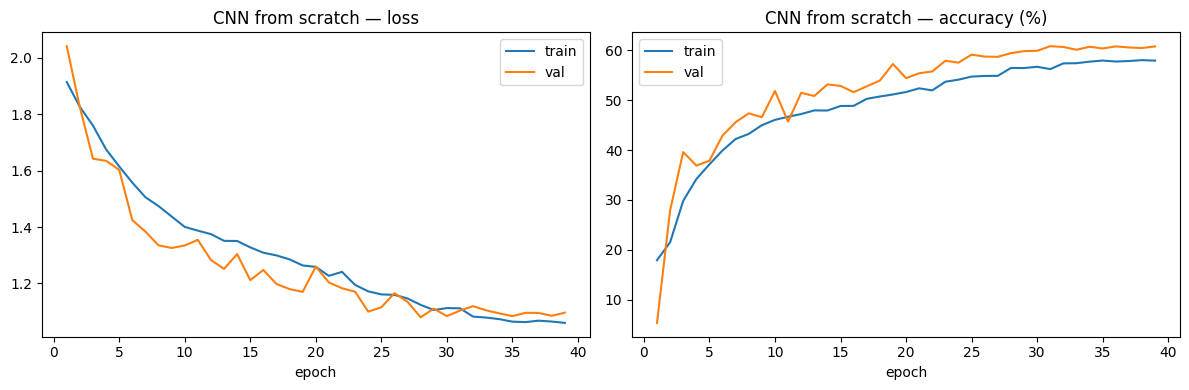


=== CNN from scratch | TEST accuracy 60.70% | macro-F1 56.70% ===
              precision    recall  f1-score   support

       angry      0.544     0.505     0.524       958
     disgust      0.405     0.694     0.512       111
        fear      0.423     0.224     0.292      1024
       happy      0.843     0.845     0.844      1774
     neutral      0.510     0.689     0.586      1233
         sad      0.465     0.436     0.450      1247
    surprise      0.716     0.811     0.761       831

    accuracy                          0.607      7178
   macro avg      0.558     0.601     0.567      7178
weighted avg      0.599     0.607     0.595      7178



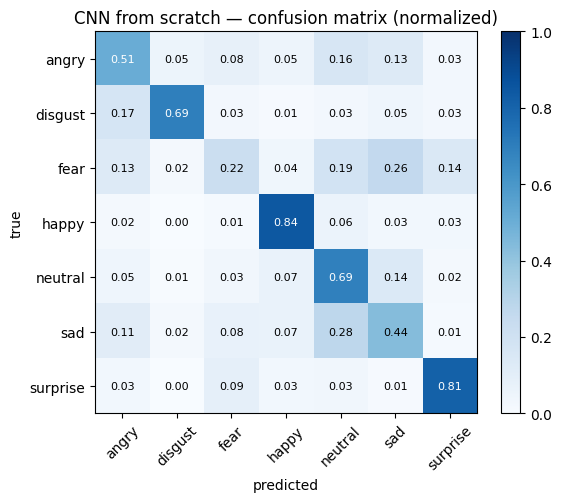

In [ ]:
opt = optim.AdamW(scratch_model.parameters(), lr=1e-3, weight_decay=1e-4)
h_scratch = fit(scratch_model, "Scratch CNN", scratch_loaders, opt, epochs=40, patience=8)
plot_history(h_scratch, "CNN from scratch")
results["CNN from scratch"] = {"params": total, "trainable": trainable, "val_acc": h_scratch["best_val_acc"],
                               "time_min": h_scratch["time_min"],
                               **evaluate_test(scratch_model, scratch_loaders[2], "CNN from scratch")}

import json
json.dump(results, open(f"{SAVE_DIR}/CNNResults.json", "w"), default=float, indent=1)

**results**
* pretrained weight and evaluations

In [ ]:
scratch_model = EmotionCNN(NUM_CLASSES).to(device)
scratch_model.load_state_dict(torch.load(f"{SAVE_DIR}/Scratch_CNN.pt"))
evaluate_test(scratch_model, scratch_loaders[2], "CNN from scratch")

## 8. Transfer Learning
**Transfer learning = feature extraction:** keep the pretrained models **frozen** (its weights never change) and train **only a new classifier head**. It is fast and low-risk.

## 8.1 Model 1 - ResNet18
 keep the pretrained ResNet18 **frozen** (its weights never change) and train **only a new classifier head**



In [ ]:
tl_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in tl_model.parameters():            # freeze everything | تجميد كل شيء
    p.requires_grad = False

tl_model.fc = nn.Sequential(               # new head (trainable by default) | رأس جديد قابل للتدريب
    nn.Dropout(0.3), nn.Linear(tl_model.fc.in_features, NUM_CLASSES)
)
tl_model = tl_model.to(device)

total, trainable = count_params(tl_model)
print(f"Params: {total:,} | trainable: {trainable:,} ({100*trainable/total:.2f}%)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]


Params: 11,180,103 | trainable: 3,591 (0.03%)


[ResNet18 TL] epoch 01/20 | train loss 1.849 acc 29.2% | val loss 1.706 acc 38.4%
[ResNet18 TL] epoch 02/20 | train loss 1.709 acc 35.3% | val loss 1.634 acc 40.8%
[ResNet18 TL] epoch 03/20 | train loss 1.682 acc 35.8% | val loss 1.610 acc 40.9%
[ResNet18 TL] epoch 04/20 | train loss 1.654 acc 37.1% | val loss 1.603 acc 40.7%
[ResNet18 TL] epoch 05/20 | train loss 1.652 acc 37.1% | val loss 1.637 acc 42.1%
[ResNet18 TL] epoch 06/20 | train loss 1.641 acc 37.0% | val loss 1.589 acc 40.0%
[ResNet18 TL] epoch 07/20 | train loss 1.642 acc 38.1% | val loss 1.581 acc 39.2%
[ResNet18 TL] epoch 08/20 | train loss 1.639 acc 37.4% | val loss 1.597 acc 40.9%
[ResNet18 TL] epoch 09/20 | train loss 1.636 acc 37.9% | val loss 1.621 acc 33.3%
[ResNet18 TL] epoch 10/20 | train loss 1.643 acc 37.3% | val loss 1.569 acc 39.8%
[ResNet18 TL] epoch 11/20 | train loss 1.645 acc 37.4% | val loss 1.587 acc 39.9%
[ResNet18 TL] epoch 12/20 | train loss 1.646 acc 37.5% | val loss 1.605 acc 41.7%
[ResNet18 TL] ep

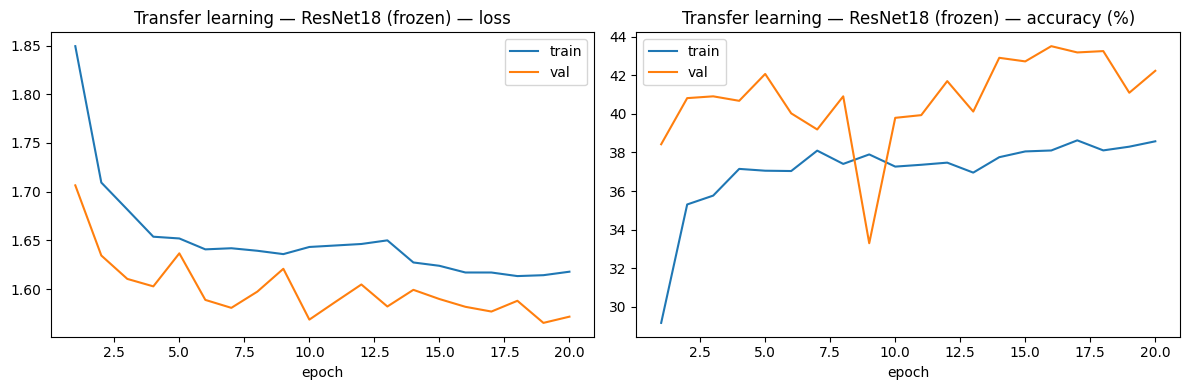


=== ResNet18 transfer learning | TEST accuracy 43.24% | macro-F1 37.32% ===
              precision    recall  f1-score   support

       angry      0.315     0.339     0.327       958
     disgust      0.093     0.333     0.146       111
        fear      0.339     0.148     0.207      1024
       happy      0.580     0.673     0.623      1774
     neutral      0.421     0.371     0.395      1233
         sad      0.369     0.353     0.361      1247
    surprise      0.517     0.599     0.555       831

    accuracy                          0.432      7178
   macro avg      0.376     0.403     0.373      7178
weighted avg      0.431     0.432     0.424      7178



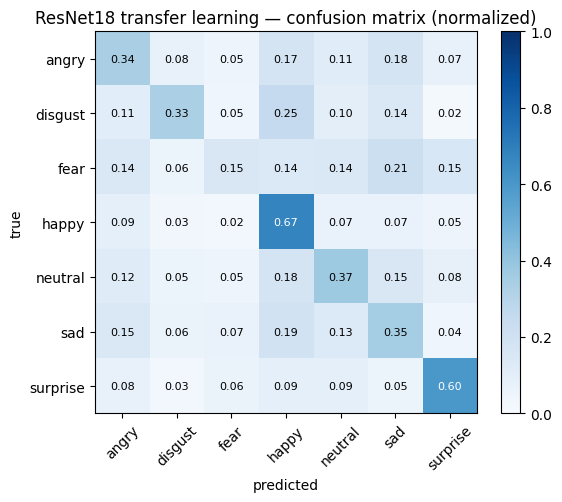

In [ ]:
opt = optim.AdamW(filter(lambda p: p.requires_grad, tl_model.parameters()), lr=1e-3, weight_decay=1e-4)
h_tl = fit(tl_model, "ResNet18 TL", pre_loaders, opt, epochs=20, patience=20)
plot_history(h_tl, "Transfer learning — ResNet18 (frozen)")
results["Transfer learning (ResNet18, frozen)"] = {"params": total, "trainable": trainable,
                               "val_acc": h_tl["best_val_acc"], "time_min": h_tl["time_min"],
                               **evaluate_test(tl_model, pre_loaders[2], "ResNet18 transfer learning")}

import json
json.dump(results, open(f"{SAVE_DIR}/ResNet18TLResults.json", "w"), default=float, indent=1)

**results**

* pretrained weight and evaluations

In [ ]:
tl_model = models.resnet18(weights=None)   # بدون تحميل أوزان ImageNet، لأننا بنحمّل أوزاننا
tl_model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(tl_model.fc.in_features, NUM_CLASSES))
tl_model = tl_model.to(device)
tl_model.load_state_dict(torch.load(f"{SAVE_DIR}/ResNet18_TL.pt"))
evaluate_test(tl_model, pre_loaders[2], "ResNet18 transfer learning")

## 8.2 Model 2 - EfficientNetB0
keep the pretrained EffiecintNetB0 **frozen** (its weights never change) and train **only a new classifier head**

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 175MB/s]

Params: 4,016,515 | trainable: 8,967 (0.22%)


[EfficientNetB0 TL] epoch 01/20 | train loss 1.702 acc 34.8% | val loss 1.618 acc 42.3%
[EfficientNetB0 TL] epoch 02/20 | train loss 1.588 acc 39.2% | val loss 1.590 acc 43.1%
[EfficientNetB0 TL] epoch 03/20 | train loss 1.552 acc 40.8% | val loss 1.553 acc 44.1%
[EfficientNetB0 TL] epoch 04/20 | train loss 1.536 acc 40.8% | val loss 1.539 acc 43.8%
[EfficientNetB0 TL] epoch 05/20 | train loss 1.531 acc 41.5% | val loss 1.536 acc 44.0%
[EfficientNetB0 TL] epoch 06/20 | train loss 1.511 acc 42.1% | val loss 1.531 acc 43.7%
[EfficientNetB0 TL] epoch 07/20 | train loss 1.504 acc 42.1% | val loss 1.514 acc 43.0%
[EfficientNetB0 TL] epoch 08/20 | train loss 1.506 acc 42.2% | val loss 1.512 acc 45.5%
[EfficientNetB0 TL] epoch 09/20 | train loss 1.506 acc 42.3% | val loss 1.523 acc 46.1%
[EfficientNetB0 TL] epoch 10/20 | train loss 1.492 acc 42.4% | val loss 1.512 acc 45.9%
[EfficientNetB0 TL] epoch 11/20 | train loss 1.493 acc 42.8% | val loss 1.509 acc 45.6%
[EfficientNetB0 TL] epoch 12/20 

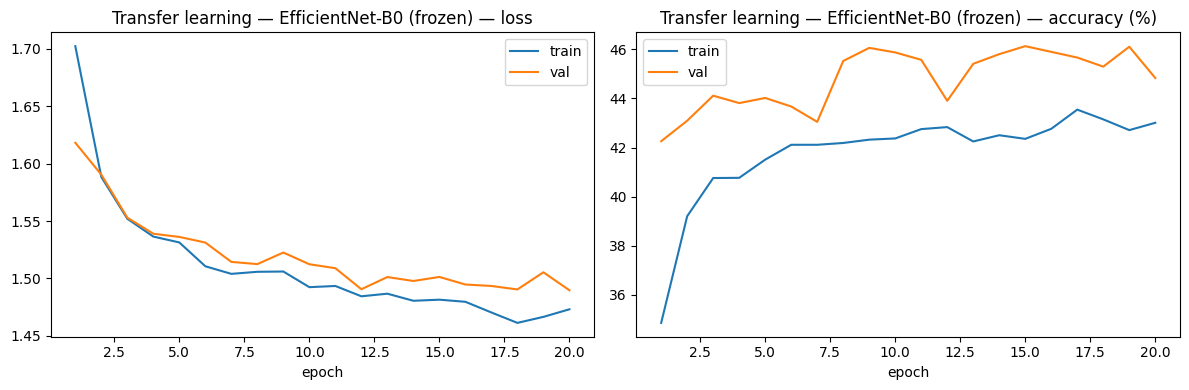


=== EfficientNet-B0 transfer learning | TEST accuracy 44.71% | macro-F1 39.71% ===
              precision    recall  f1-score   support

       angry      0.340     0.413     0.373       958
     disgust      0.103     0.450     0.168       111
        fear      0.384     0.232     0.290      1024
       happy      0.559     0.676     0.612      1774
     neutral      0.448     0.357     0.397      1233
         sad      0.416     0.282     0.336      1247
    surprise      0.569     0.641     0.603       831

    accuracy                          0.447      7178
   macro avg      0.403     0.436     0.397      7178
weighted avg      0.455     0.447     0.442      7178



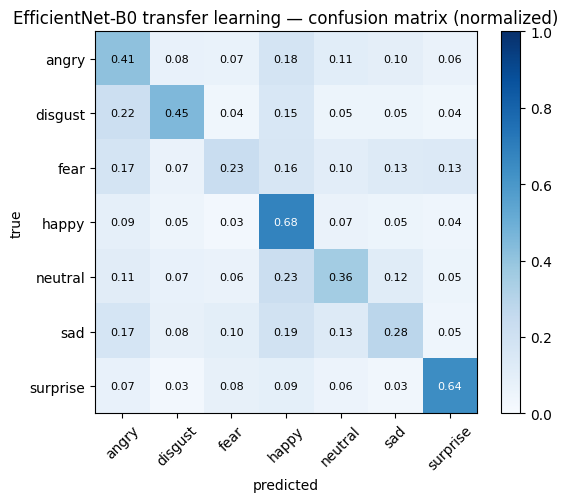

In [ ]:

# Transfer Learning — EfficientNet-B0 (frozen backbone)

tl_model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Freeze everything
for p in tl_model.parameters():
    p.requires_grad = False

# Replace the classifier with a new trainable head
in_features = tl_model.classifier[1].in_features
tl_model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, NUM_CLASSES)
)

tl_model = tl_model.to(device)

total, trainable = count_params(tl_model)
print(
    f"Params: {total:,} | trainable: {trainable:,} "
    f"({100 * trainable / total:.2f}%)"
)

opt = optim.AdamW(
    filter(lambda p: p.requires_grad, tl_model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

h_tl = fit(
    tl_model,
    "EfficientNetB0 TL",
    pre_loaders,
    opt,
    epochs=20,
    patience=20
)

plot_history(h_tl, "Transfer learning — EfficientNet-B0 (frozen)")

results["Transfer learning (EfficientNet-B0, frozen)"] = {
    "params": total,
    "trainable": trainable,
    "val_acc": h_tl["best_val_acc"],
    "time_min": h_tl["time_min"],
    **evaluate_test(
        tl_model,
        pre_loaders[2],
        "EfficientNet-B0 transfer learning"
    )
}

import json
json.dump(
    results,
    open(f"{SAVE_DIR}/EfficientNetB0-TL-Results.json", "w"),
    default=float,
    indent=1
)

In [ ]:
tl_model = models.efficientnet_b0(weights=None)   # بدون تحميل أوزان ImageNet، لأننا بنحمّل أوزاننا
tl_model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(tl_model.fc.in_features, NUM_CLASSES))
tl_model = tl_model.to(device)
tl_model.load_state_dict(torch.load(f"{SAVE_DIR}/EfficientNetB0_TL.pt"))
evaluate_test(tl_model, pre_loaders[2], "EfficientNetB0 transfer learning")

## 9. Partial Fine-Tuning
let part of the pretrained backbone learn. We do it in **two phases**:
1. **Warm-up:** backbone frozen, train only the new head (so random head weights don't damage the pretrained features).
2. **Fine-tune:** unfreeze the **last blocks** of the backbone and train them with a **much smaller learning rate** than the head (`1e-4` vs `1e-3`).


## 9.1 EfficientNetB0
let part of the pretrained backbone learn. We do it in **two phases**:
1. **Warm-up:** backbone frozen, train only the new head (so random head weights don't damage the pretrained features).
2. **Fine-tune:** unfreeze the **last blocks** of the backbone and train them with a **much smaller learning rate** than the head (`1e-4` vs `1e-3`).

In [ ]:
ft_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
ft_model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(ft_model.classifier[1].in_features, NUM_CLASSES))
ft_model = ft_model.to(device)
print("Number of feature blocks:", len(ft_model.features))

# ---- Phase 1: warm-up (backbone frozen) | المرحلة 1: الـ backbone مجمّد ----
for p in ft_model.features.parameters():
    p.requires_grad = False
opt = optim.AdamW(ft_model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
h_ft = fit(ft_model, "EffNet-B0 warm-up", pre_loaders, opt, epochs=4, patience=4)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 148MB/s]


Number of feature blocks: 9
[EffNet-B0 warm-up] epoch 01/4 | train loss 1.710 acc 33.4% | val loss 1.639 acc 41.3%
[EffNet-B0 warm-up] epoch 02/4 | train loss 1.584 acc 39.4% | val loss 1.570 acc 44.0%
[EffNet-B0 warm-up] epoch 03/4 | train loss 1.565 acc 39.9% | val loss 1.563 acc 44.7%
[EffNet-B0 warm-up] epoch 04/4 | train loss 1.540 acc 41.1% | val loss 1.538 acc 44.1%


In [ ]:
# ---- Phase 2: unfreeze the last blocks + discriminative learning rates ----
# ---- المرحلة 2: نفكّ تجميد آخر الكتل مع learning rate مختلف لكل جزء ----
for p in ft_model.features[5:].parameters():
    p.requires_grad = True

opt = optim.AdamW([
    {"params": ft_model.features[5:].parameters(), "lr": 1e-4},   # backbone: small lr
    {"params": ft_model.classifier.parameters(),   "lr": 1e-3},   # head: larger lr
], weight_decay=1e-4)

total, trainable = count_params(ft_model)
print(f"Params: {total:,} | trainable: {trainable:,} ({100*trainable/total:.1f}%)")

h_ft = fit(ft_model, "EffNet-B0 fine-tune", pre_loaders, opt, epochs=20, patience=20, history=h_ft)
plot_history(h_ft, "Fine-tuning — EfficientNet-B0 (warm-up + last blocks)")
results["Fine-tuning (EfficientNet-B0)"] = {"params": total, "trainable": trainable,
                               "val_acc": h_ft["best_val_acc"], "time_min": h_ft["time_min"],
                               **evaluate_test(ft_model, pre_loaders[2], "EfficientNet-B0 fine-tuning")}

import json
json.dump(results, open(f"{SAVE_DIR}/EfficientNetB0-FT-Results.json", "w"), default=float, indent=1)

Params: 4,016,515 | trainable: 3,707,855 (92.3%)
[EffNet-B0 fine-tune] epoch 01/20 | train loss 1.627 acc 37.7% | val loss 1.445 acc 44.6%
[EffNet-B0 fine-tune] epoch 02/20 | train loss 1.335 acc 47.5% | val loss 1.305 acc 51.1%
[EffNet-B0 fine-tune] epoch 03/20 | train loss 1.186 acc 53.1% | val loss 1.213 acc 54.7%
[EffNet-B0 fine-tune] epoch 04/20 | train loss 1.083 acc 56.9% | val loss 1.156 acc 56.7%
[EffNet-B0 fine-tune] epoch 05/20 | train loss 0.996 acc 59.4% | val loss 1.160 acc 58.9%
[EffNet-B0 fine-tune] epoch 06/20 | train loss 0.938 acc 61.8% | val loss 1.143 acc 59.7%
[EffNet-B0 fine-tune] epoch 07/20 | train loss 0.882 acc 64.0% | val loss 1.171 acc 61.0%
[EffNet-B0 fine-tune] epoch 08/20 | train loss 0.833 acc 65.8% | val loss 1.205 acc 61.9%
[EffNet-B0 fine-tune] epoch 09/20 | train loss 0.780 acc 67.8% | val loss 1.157 acc 62.4%
[EffNet-B0 fine-tune] epoch 10/20 | train loss 0.736 acc 69.7% | val loss 1.191 acc 62.9%
[EffNet-B0 fine-tune] epoch 11/20 | train loss 0.69


=== EfficientNet-B0 fine-tuning | TEST accuracy 64.80% | macro-F1 62.91% ===
              precision    recall  f1-score   support

       angry      0.553     0.602     0.577       958
     disgust      0.573     0.676     0.620       111
        fear      0.531     0.416     0.466      1024
       happy      0.847     0.837     0.842      1774
     neutral      0.598     0.614     0.606      1233
         sad      0.523     0.533     0.528      1247
    surprise      0.732     0.801     0.765       831

    accuracy                          0.648      7178
   macro avg      0.622     0.640     0.629      7178
weighted avg      0.646     0.648     0.646      7178



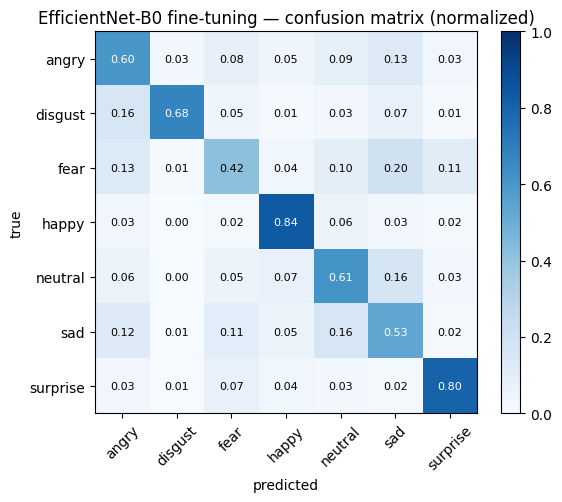

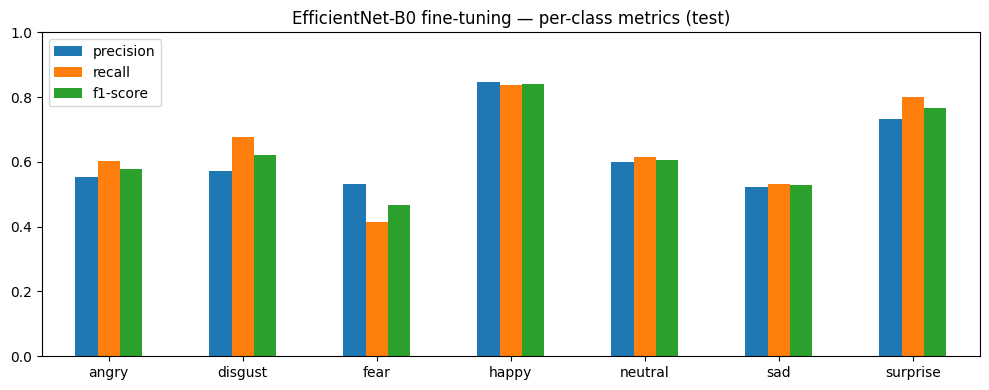

In [11]:
# 1) نبني النموذج ونحمّل أفضل أوزان
ft_model = models.efficientnet_b0(weights=None)
ft_model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(ft_model.classifier[1].in_features, NUM_CLASSES))
ft_model = ft_model.to(device)
ft_model.load_state_dict(torch.load(f"{SAVE_DIR}/EffNet-B0_fine-tune.pt", map_location=device))

# 2) التقييم على الاختبار: يطبع accuracy و macro-F1 و precision/recall/F1 لكل صنف، ويرسم الـ confusion matrix
res = evaluate_test(ft_model, pre_loaders[2], "EfficientNet-B0 fine-tuning")

# 3) رسمة بار: precision / recall / F1 لكل شعور
@torch.no_grad()
def get_preds(model, loader):
    model.eval(); P, L = [], []
    for x, y in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x.to(device))
        P.append(out.argmax(1).cpu()); L.append(y)
    return torch.cat(P).numpy(), torch.cat(L).numpy()

preds, labels = get_preds(ft_model, pre_loaders[2])
rep = classification_report(labels, preds, target_names=CLASS_NAMES, output_dict=True)
dfm = pd.DataFrame({c: rep[c] for c in CLASS_NAMES}).T[["precision", "recall", "f1-score"]]

dfm.plot.bar(figsize=(10, 4), rot=0)
plt.ylim(0, 1); plt.title("EfficientNet-B0 fine-tuning — per-class metrics (test)")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/per_class_metrics_effnet_ft.png", dpi=150, bbox_inches="tight")
plt.show()

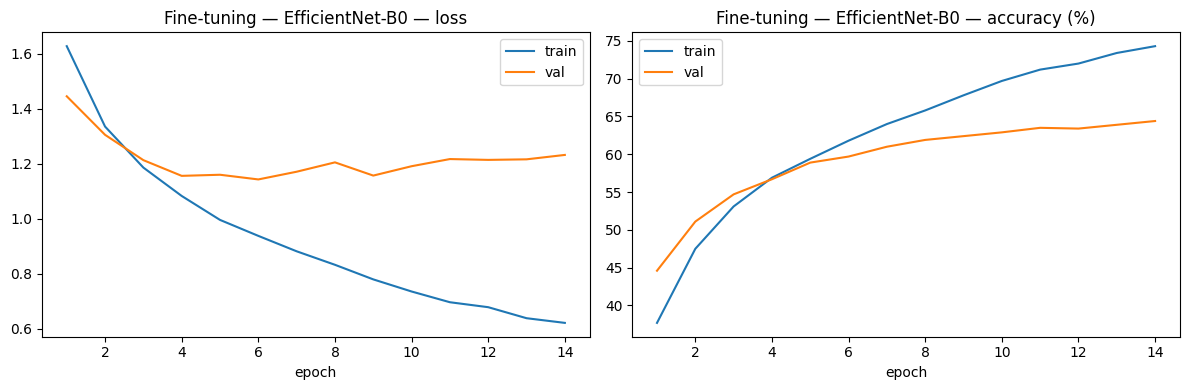

<Figure size 640x480 with 0 Axes>

In [12]:
import re

log = """
[EffNet-B0 fine-tune] epoch 01/20 | train loss 1.627 acc 37.7% | val loss 1.445 acc 44.6%
[EffNet-B0 fine-tune] epoch 02/20 | train loss 1.335 acc 47.5% | val loss 1.305 acc 51.1%
[EffNet-B0 fine-tune] epoch 03/20 | train loss 1.186 acc 53.1% | val loss 1.213 acc 54.7%
[EffNet-B0 fine-tune] epoch 04/20 | train loss 1.083 acc 56.9% | val loss 1.156 acc 56.7%
[EffNet-B0 fine-tune] epoch 05/20 | train loss 0.996 acc 59.4% | val loss 1.160 acc 58.9%
[EffNet-B0 fine-tune] epoch 06/20 | train loss 0.938 acc 61.8% | val loss 1.143 acc 59.7%
[EffNet-B0 fine-tune] epoch 07/20 | train loss 0.882 acc 64.0% | val loss 1.171 acc 61.0%
[EffNet-B0 fine-tune] epoch 08/20 | train loss 0.833 acc 65.8% | val loss 1.205 acc 61.9%
[EffNet-B0 fine-tune] epoch 09/20 | train loss 0.780 acc 67.8% | val loss 1.157 acc 62.4%
[EffNet-B0 fine-tune] epoch 10/20 | train loss 0.736 acc 69.7% | val loss 1.191 acc 62.9%
[EffNet-B0 fine-tune] epoch 11/20 | train loss 0.697 acc 71.2% | val loss 1.217 acc 63.5%
[EffNet-B0 fine-tune] epoch 12/20 | train loss 0.679 acc 72.0% | val loss 1.214 acc 63.4%
[EffNet-B0 fine-tune] epoch 13/20 | train loss 0.639 acc 73.4% | val loss 1.216 acc 63.9%
[EffNet-B0 fine-tune] epoch 14/20 | train loss 0.622 acc 74.3% | val loss 1.232 acc 64.4%
"""

pat = re.compile(r"train loss ([\d.]+) acc ([\d.]+)% \| val loss ([\d.]+) acc ([\d.]+)%")
rows = pat.findall(log)
h = {"train_loss": [float(r[0]) for r in rows], "val_loss": [float(r[2]) for r in rows],
     "train_acc":  [float(r[1]) for r in rows], "val_acc":  [float(r[3]) for r in rows]}

plot_history(h, "Fine-tuning — EfficientNet-B0")
plt.savefig(f"{SAVE_DIR}/curve_effnet_ft.png", dpi=150, bbox_inches="tight")

**Results**

* pretrained weight and evaluations

In [ ]:
ft_model = models.efficientnet_b0(weights=None)
ft_model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(ft_model.classifier[1].in_features, NUM_CLASSES))
ft_model = ft_model.to(device)
ft_model.load_state_dict(torch.load(f"{SAVE_DIR}/EffNet-B0_fine-tune.pt"))
evaluate_test(ft_model, pre_loaders[2], "EfficientNet-B0 fine-tuning")

## 9.1 ResNet18
let part of the pretrained backbone learn. We do it in **two phases**:
1. **Warm-up:** backbone frozen, train only the new head (so random head weights don't damage the pretrained features).
2. **Fine-tune:** unfreeze the **last blocks** of the backbone and train them with a **much smaller learning rate** than the head (`1e-4` vs `1e-3`).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s]


ResNet18 layer4 blocks: 2
[ResNet18 warm-up] epoch 01/4 | train loss 1.867 acc 28.6% | val loss 1.680 acc 38.4%
[ResNet18 warm-up] epoch 02/4 | train loss 1.706 acc 35.0% | val loss 1.640 acc 40.8%
[ResNet18 warm-up] epoch 03/4 | train loss 1.682 acc 36.2% | val loss 1.604 acc 38.8%
[ResNet18 warm-up] epoch 04/4 | train loss 1.659 acc 36.8% | val loss 1.602 acc 40.3%
Params: 11,180,103 | trainable: 8,397,319 (75.1%)
[ResNet18 fine-tune] epoch 01/20 | train loss 1.540 acc 42.2% | val loss 1.373 acc 46.9%
[ResNet18 fine-tune] epoch 02/20 | train loss 1.261 acc 51.3% | val loss 1.296 acc 51.6%
[ResNet18 fine-tune] epoch 03/20 | train loss 1.144 acc 55.1% | val loss 1.246 acc 54.8%
[ResNet18 fine-tune] epoch 04/20 | train loss 1.058 acc 58.0% | val loss 1.240 acc 56.5%
[ResNet18 fine-tune] epoch 05/20 | train loss 0.974 acc 61.1% | val loss 1.394 acc 59.0%
[ResNet18 fine-tune] epoch 06/20 | train loss 0.915 acc 63.3% | val loss 1.237 acc 57.6%
[ResNet18 fine-tune] epoch 07/20 | train loss 

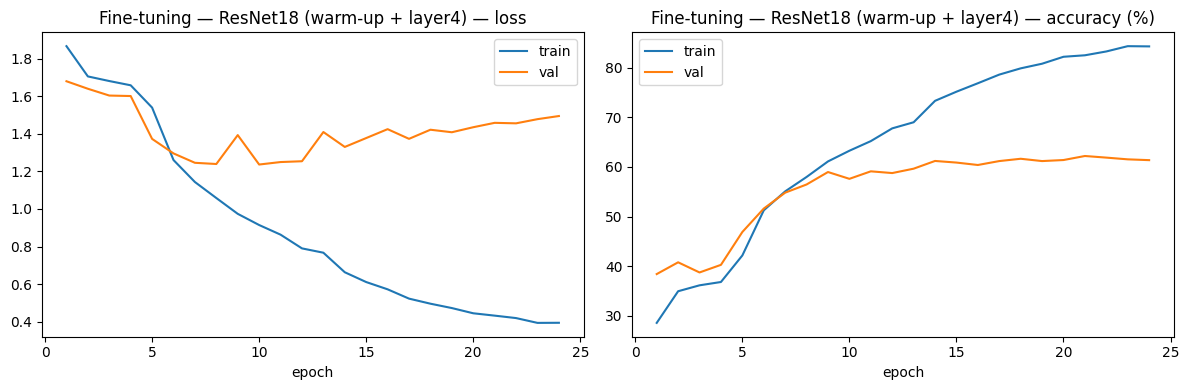


=== ResNet18 fine-tuning | TEST accuracy 62.18% | macro-F1 60.67% ===
              precision    recall  f1-score   support

       angry      0.530     0.519     0.525       958
     disgust      0.603     0.631     0.617       111
        fear      0.476     0.429     0.451      1024
       happy      0.833     0.809     0.821      1774
     neutral      0.567     0.575     0.571      1233
         sad      0.498     0.509     0.503      1247
    surprise      0.711     0.815     0.759       831

    accuracy                          0.622      7178
   macro avg      0.603     0.612     0.607      7178
weighted avg      0.620     0.622     0.620      7178



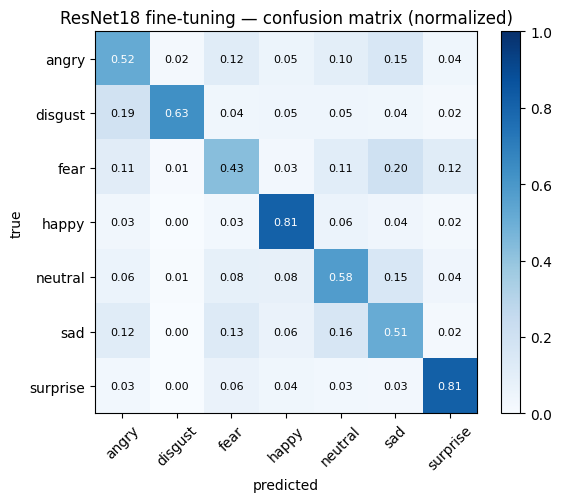

In [13]:

# Fine-Tuning — ResNet18

ft_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

ft_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(ft_model.fc.in_features, NUM_CLASSES)
)

ft_model = ft_model.to(device)
print("ResNet18 layer4 blocks:", len(ft_model.layer4))

# ---- Phase 1: warm-up (backbone frozen) ----
for p in ft_model.parameters():
    p.requires_grad = False

for p in ft_model.fc.parameters():
    p.requires_grad = True

opt = optim.AdamW(
    ft_model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

h_ft = fit(
    ft_model,
    "ResNet18 warm-up",
    pre_loaders,
    opt,
    epochs=4,
    patience=4
)

# ---- Phase 2: unfreeze layer4 + different learning rates ----
for p in ft_model.layer4.parameters():
    p.requires_grad = True

opt = optim.AdamW([
    {
        "params": ft_model.layer4.parameters(),
        "lr": 1e-4
    },
    {
        "params": ft_model.fc.parameters(),
        "lr": 1e-3
    }
], weight_decay=1e-4)

total, trainable = count_params(ft_model)
print(
    f"Params: {total:,} | trainable: {trainable:,} "
    f"({100 * trainable / total:.1f}%)"
)

h_ft = fit(
    ft_model,
    "ResNet18 fine-tune",
    pre_loaders,
    opt,
    epochs=20,
    patience=20,
    history=h_ft
)

plot_history(
    h_ft,
    "Fine-tuning — ResNet18 (warm-up + layer4)"
)

results["Fine-tuning (ResNet18)"] = {
    "params": total,
    "trainable": trainable,
    "val_acc": h_ft["best_val_acc"],
    "time_min": h_ft["time_min"],
    **evaluate_test(
        ft_model,
        pre_loaders[2],
        "ResNet18 fine-tuning"
    )
}

import json
json.dump(
    results,
    open(f"{SAVE_DIR}/ResNet18-FT-Results.json", "w"),
    default=float,
    indent=1
)

In [ ]:

ft_model = models.resnet18(weights=None)

ft_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(ft_model.fc.in_features, NUM_CLASSES)
)

ft_model = ft_model.to(device)

ft_model.load_state_dict(
    torch.load(
        f"{SAVE_DIR}/ResNet18_fine-tune.pt",
        map_location=device
    )
)

evaluate_test(
    ft_model,
    pre_loaders[2],
    "ResNet18 fine-tuning"
)

## 10. Evaluation of CNN, Transfer Learning, fine-tuning

- CNN
- Transfer learning

      - ResNet18
      - EfficientNetB0

- Partial Fine-Tuning

      - EfficientNetB0
      - ResNet18

Files in SAVE_DIR: ['EffNet-B0_fine-tune.pt', 'EffNet-B0_warm-up.pt', 'EfficientNetB0_TL.pt', 'ResNet18_TL.pt', 'ResNet18_fine-tune.pt', 'ResNet18_warm-up.pt', 'Scratch_CNN.pt']
[ok] CNN (scratch): acc 60.70%
[ok] TL ResNet18: acc 43.24%
[ok] TL EfficientNet-B0: acc 44.71%
[ok] FT ResNet18: acc 62.18%
[ok] FT EfficientNet-B0: acc 64.85%


,Accuracy,Precision,Recall,F1 (macro)
CNN (scratch),60.70,55.80,60.06,56.70
TL ResNet18,43.24,37.64,40.25,37.32
TL EfficientNet-B0,44.71,40.29,43.62,39.71
FT ResNet18,62.18,60.26,61.24,60.67
FT EfficientNet-B0,64.85,62.46,64.12,63.16


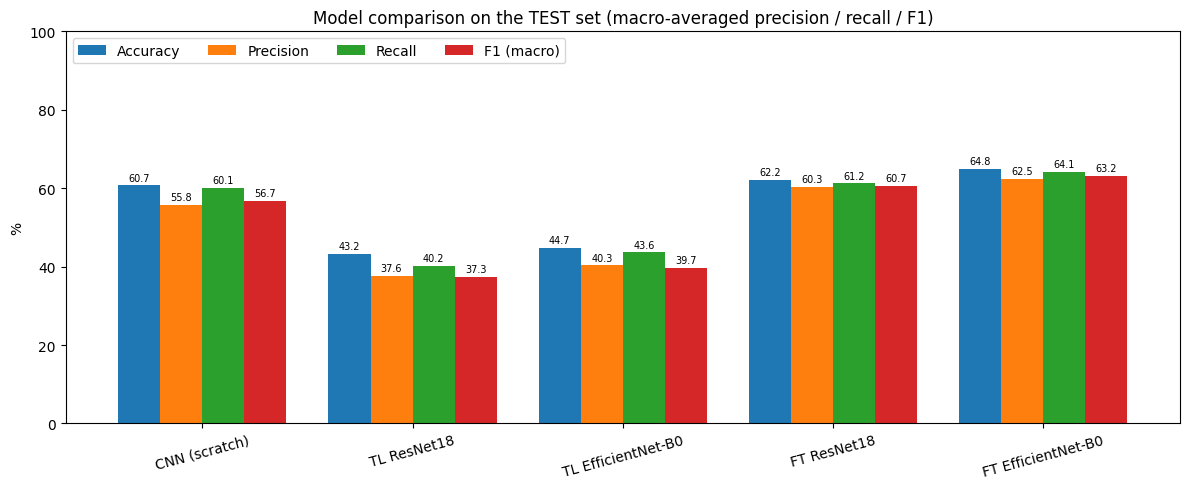

,CNN (scratch),TL ResNet18,TL EfficientNet-B0,FT ResNet18,FT EfficientNet-B0
angry,52.4,32.7,37.3,52.5,57.6
disgust,51.2,14.6,16.8,61.7,63.1
fear,29.2,20.7,29.0,45.1,47.7
happy,84.4,62.3,61.2,82.1,84.3
neutral,58.6,39.5,39.7,57.1,60.6
sad,45.0,36.1,33.6,50.3,52.3
surprise,76.1,55.5,60.3,75.9,76.6


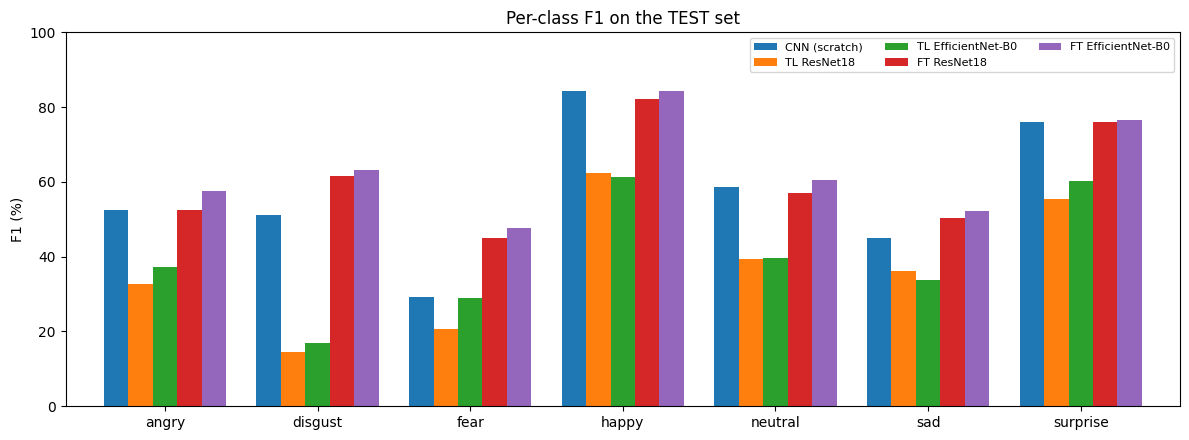

In [14]:
# =====================================================================
# CELL A — Load the 5 saved models, compute metrics, table + charts
# =====================================================================
import os
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, f1_score

# ---------- 1) Builders: must match the architecture used in training ----------
# لازم تطابق البنية اللي دربتي فيها بالضبط
def build_scratch():
    return EmotionCNN(NUM_CLASSES)

def build_resnet():
    m = models.resnet18(weights=None)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m

def build_effnet():
    m = models.efficientnet_b0(weights=None)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, NUM_CLASSES))
    return m

# ---------- 2) Config: edit the file names to match what is on your Drive ----------
CONFIG = {
    "CNN (scratch)":      dict(build=build_scratch, file="Scratch_CNN.pt",         loaders=scratch_loaders),
    "TL ResNet18":        dict(build=build_resnet,  file="ResNet18_TL.pt",          loaders=pre_loaders),
    "TL EfficientNet-B0": dict(build=build_effnet,  file="EfficientNetB0_TL.pt",   loaders=pre_loaders),   # <- check name
    "FT ResNet18":        dict(build=build_resnet,  file="ResNet18_fine-tune.pt",   loaders=pre_loaders),
    "FT EfficientNet-B0": dict(build=build_effnet,  file="EffNet-B0_fine-tune.pt",  loaders=pre_loaders),
}
print("Files in SAVE_DIR:", sorted(f for f in os.listdir(SAVE_DIR) if f.endswith(".pt")))

# ---------- 3) Predict on the TEST set with every model ----------
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    P, C = [], []
    for x, _ in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x.to(device))
        conf, pred = out.float().softmax(1).max(1)
        P.append(pred.cpu()); C.append(conf.cpu())
    return torch.cat(P).numpy(), torch.cat(C).numpy()

y_true = np.array(raw_test.targets)          # test loaders use shuffle=False, so order matches
preds, confs, rows = {}, {}, {}

for name, cfg in CONFIG.items():
    path = f"{SAVE_DIR}/{cfg['file']}"
    if not os.path.exists(path):
        print(f"[skipped] {name}: file not found -> {cfg['file']}")
        continue
    model = cfg["build"]().to(device)
    model.load_state_dict(torch.load(path, map_location=device))
    preds[name], confs[name] = predict_all(model, cfg["loaders"][2])
    p, r, f1, _ = precision_recall_fscore_support(y_true, preds[name], average="macro", zero_division=0)
    rows[name] = {"Accuracy": 100 * accuracy_score(y_true, preds[name]),
                  "Precision": 100 * p, "Recall": 100 * r, "F1 (macro)": 100 * f1}
    print(f"[ok] {name}: acc {rows[name]['Accuracy']:.2f}%")
    del model
    torch.cuda.empty_cache()

# ---------- 4) Comparison table ----------
df = pd.DataFrame(rows).T.round(2)
display(df.style.highlight_max(axis=0, color="#c6efce").format("{:.2f}"))   # best value per column in green
df.to_csv(f"{SAVE_DIR}/comparison_table.csv")

# ---------- 5) Grouped bar chart: all models x all metrics ----------
ax = df.plot.bar(figsize=(12, 5), rot=15, width=0.8)
ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.set_title("Model comparison on the TEST set (macro-averaged precision / recall / F1)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=7, padding=2)
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/comparison_chart.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 6) Per-class F1: which emotions are hard for which model ----------
f1_cls = pd.DataFrame({n: 100 * f1_score(y_true, p, average=None, labels=list(range(NUM_CLASSES)))
                       for n, p in preds.items()}, index=CLASS_NAMES)
display(f1_cls.round(1))
f1_cls.plot.bar(figsize=(12, 4.5), rot=0, width=0.8)
plt.ylabel("F1 (%)"); plt.ylim(0, 100); plt.title("Per-class F1 on the TEST set")
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/per_class_f1_all_models.png", dpi=150, bbox_inches="tight")
plt.show()



## 11. Model Visualization
- CNN
- Transfer learning ResNet18
- Transfer learning EfficientNetB0
- Partial fine-tuning ResNet18
- Partial fine-tuning EfficentNetB0

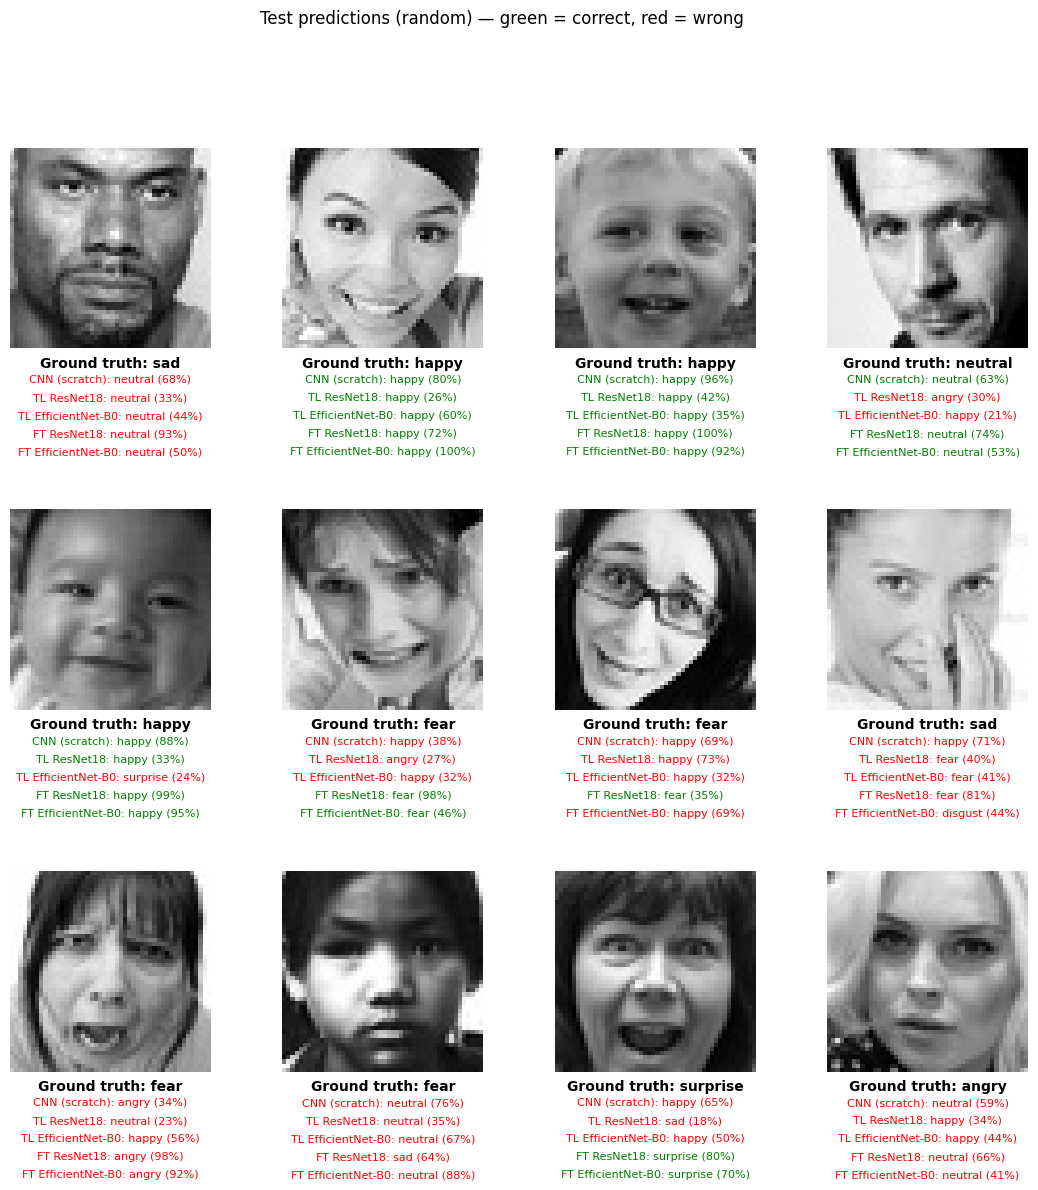

In [16]:
# =====================================================================
# CELL B — Predictions on images: ground truth + every model's prediction
# (green = correct, red = wrong
# =====================================================================
def show_grid(n=12, cols=4, pick="random", seed=0):
    """pick="random": random test images
       pick="hard"  : images where the FEWEST models are correct (great for the discussion)"""
    names = list(preds)
    rng = np.random.RandomState(seed)
    if pick == "hard":
        n_correct = sum((preds[m] == y_true).astype(int) for m in names)
        idxs = np.argsort(n_correct + rng.rand(len(y_true)) * 0.5)[:n]      # random tie-breaking
    else:
        idxs = rng.choice(len(y_true), n, replace=False)

    nrows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * 3.4, nrows * (2.6 + 0.28 * len(names))))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")

    for ax, i in zip(axes, idxs):
        img, _ = raw_test[int(i)]
        ax.imshow(img.convert("L"), cmap="gray")
        ax.text(0.5, -0.04, f"Ground truth: {CLASS_NAMES[y_true[i]]}", transform=ax.transAxes,
                ha="center", va="top", fontsize=10, fontweight="bold")
        for k, m in enumerate(names):
            ok = preds[m][i] == y_true[i]
            ax.text(0.5, -0.04 - 0.09 * (k + 1),
                    f"{m}: {CLASS_NAMES[preds[m][i]]} ({100 * confs[m][i]:.0f}%)",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8,
                    color="green" if ok else "red")

    plt.subplots_adjust(hspace=0.8, wspace=0.15)
    fig.suptitle(f"Test predictions ({pick}) — green = correct, red = wrong", y=0.995)
    plt.savefig(f"{SAVE_DIR}/predictions_{pick}_seed{seed}.png", dpi=130, bbox_inches="tight")
    plt.show()

show_grid(n=12, pick="random", seed=0)   # change seed to see other images |


## Winner model

fine tuning **EfficientNetB0**

## 12. Model optimization
* hardware acceleration ~ CPU to T4 GPU

,Latency ms (batch=1),Throughput img/s (batch=64),Size MB,Test acc %
Variant,,,,
GPU FP32 (baseline),21.38,1747.95,16.35,64.84
GPU FP16,9.81,3802.02,8.25,64.81


Latency speed-up x2.18 | Throughput x2.18 | Accuracy change -0.03 points


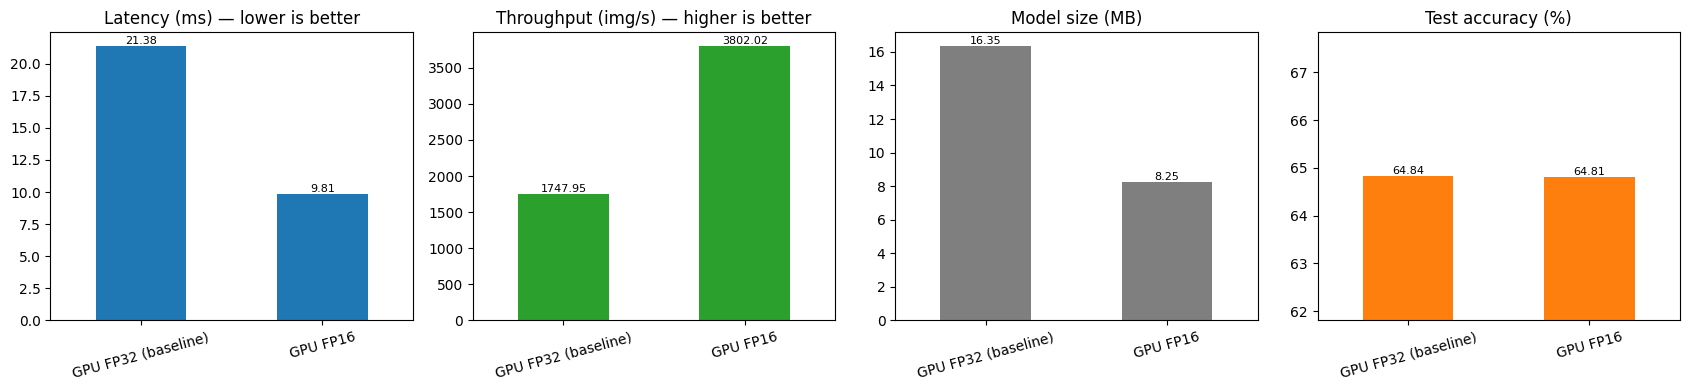

In [17]:
# =====================================================================
# FP16 vs FP32 on GPU — best model (Fine-tuned EfficientNet-B0)
# مقارنة FP32 (الأصل) مع FP16 (المحسّن) على الـ GPU: سرعة + حجم + دقة
#
# شغّليها بعد: drive.mount + SAVE_DIR + الخلايا الأساسية لين قسم 6 (بدون تدريب)
# لازم الـ GPU يكون شغّال (Runtime -> T4 GPU)
# =====================================================================
import os, time, copy

assert device.type == "cuda", "FP16 needs a GPU: Runtime -> Change runtime type -> T4 GPU"

# ---------- 1) Load the best model ----------
PT_PATH = f"{SAVE_DIR}/EffNet-B0_fine-tune.pt"
best = models.efficientnet_b0(weights=None)
best.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(best.classifier[1].in_features, NUM_CLASSES))
best.load_state_dict(torch.load(PT_PATH, map_location="cpu"))

fp32 = copy.deepcopy(best).to(device).eval()                 # original
fp16 = copy.deepcopy(best).to(device).half().eval()          # optimized: weights in half precision
torch.backends.cudnn.benchmark = True

# ---------- 2) Helpers ----------
@torch.no_grad()
def run(model, x, half):
    x = x.to(device)
    return model(x.half() if half else x).float()

def timeit(fn, n, warm=10):
    for _ in range(warm): fn()
    torch.cuda.synchronize(); t = time.perf_counter()
    for _ in range(n): fn()
    torch.cuda.synchronize()
    return (time.perf_counter() - t) / n

def accuracy(model, half):
    correct = n = 0
    for x, y in pre_loaders[2]:                              # TEST set
        correct += (run(model, x, half).argmax(1).cpu() == y).sum().item(); n += len(y)
    return 100 * correct / n

def row(name, model, half, size_mb):
    x1 = torch.randn(1,  3, IMG_SIZE, IMG_SIZE)
    xb = torch.randn(64, 3, IMG_SIZE, IMG_SIZE)
    return {"Variant": name,
            "Latency ms (batch=1)":        timeit(lambda: run(model, x1, half), 100) * 1000,
            "Throughput img/s (batch=64)": 64 / timeit(lambda: run(model, xb, half), 20),
            "Size MB":                     size_mb,
            "Test acc %":                  accuracy(model, half)}

# ---------- 3) Measure ----------
torch.save(fp16.state_dict(), "/tmp/effnet_fp16.pt")
rows = [row("GPU FP32 (baseline)", fp32, False, os.path.getsize(PT_PATH) / 1e6),
        row("GPU FP16",            fp16, True,  os.path.getsize("/tmp/effnet_fp16.pt") / 1e6)]

res = pd.DataFrame(rows).set_index("Variant").round(2)
display(res)
res.to_csv(f"{SAVE_DIR}/fp16_vs_fp32.csv")

speedup = res.loc["GPU FP32 (baseline)", "Latency ms (batch=1)"] / res.loc["GPU FP16", "Latency ms (batch=1)"]
thr_gain = res.loc["GPU FP16", "Throughput img/s (batch=64)"] / res.loc["GPU FP32 (baseline)", "Throughput img/s (batch=64)"]
acc_drop = res.loc["GPU FP32 (baseline)", "Test acc %"] - res.loc["GPU FP16", "Test acc %"]
print(f"Latency speed-up x{speedup:.2f} | Throughput x{thr_gain:.2f} | Accuracy change {-acc_drop:+.2f} points")

# ---------- 4) Chart ----------
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, col, title, color in zip(ax,
        ["Latency ms (batch=1)", "Throughput img/s (batch=64)", "Size MB", "Test acc %"],
        ["Latency (ms) — lower is better", "Throughput (img/s) — higher is better", "Model size (MB)", "Test accuracy (%)"],
        ["tab:blue", "tab:green", "tab:gray", "tab:orange"]):
    res[col].plot.bar(ax=a, rot=15, color=color); a.set_title(title); a.set_xlabel("")
    for c in a.containers: a.bar_label(c, fmt="%.2f", fontsize=8)
ax[3].set_ylim(res["Test acc %"].min() - 3, res["Test acc %"].max() + 3)     # zoom so tiny differences are visible
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fp16_vs_fp32_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. model deployment
using ONNX

In [11]:
%pip install -q onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 13.3 MB/s eta 0:00:00


In [12]:
best = models.efficientnet_b0(weights=None)
best.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(best.classifier[1].in_features, NUM_CLASSES))
best.load_state_dict(torch.load(f"{SAVE_DIR}/EffNet-B0_fine-tune.pt", map_location="cpu"))
best.eval().cpu()

dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
ONNX_PATH = f"{SAVE_DIR}/emotion_effnetb0_fp32.onnx"
kw = dict(input_names=["image"], output_names=["logits"],
          dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
try:
    torch.onnx.export(best, dummy, ONNX_PATH, dynamo=False, **kw)
except TypeError:
    torch.onnx.export(best, dummy, ONNX_PATH, **kw)

# تحقق أن ONNX يعطي نفس نتايج PyTorch
!pip install -q onnx onnxruntime
import onnxruntime as ort
sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
out = sess.run(None, {"image": dummy.numpy()})[0]
print("max diff:", np.abs(out - best(dummy).detach().numpy()).max())   # لازم رقم صغير جداً (حوالي 1e-5 أو أقل)

/tmp/ipykernel_3010/385809167.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(best, dummy, ONNX_PATH, dynamo=False, **kw)


max diff: 4.7683716e-06


In [13]:
from google.colab import files
files.download(ONNX_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Live streaming